<a href="https://colab.research.google.com/github/harshhlf2024-cmyk/Minor-Project/blob/main/Minor_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)

## 2. Load the Kaggle dataset

In [6]:
from google.colab import files
uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

Saving diabetes.csv to diabetes (2).csv


In [7]:
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 3. Check and clean the data

In [8]:
print("Missing values before cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [9]:
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[zero_columns] = df[zero_columns].replace(0, np.nan)

In [10]:
print("\\nMissing values after replacing invalid zeros:")
print(df.isnull().sum())

\nMissing values after replacing invalid zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


## 4. Separate input and output

In [11]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


## 5. Build and train Logistic Regression model

In [12]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Model training completed.")

Model training completed.


## 6. Evaluate the model

In [13]:
print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 3))

print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.734
Precision: 0.603
Recall   : 0.704
F1-score : 0.65
ROC-AUC  : 0.813
\nClassification report:
              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154



## 7. Confusion matrix

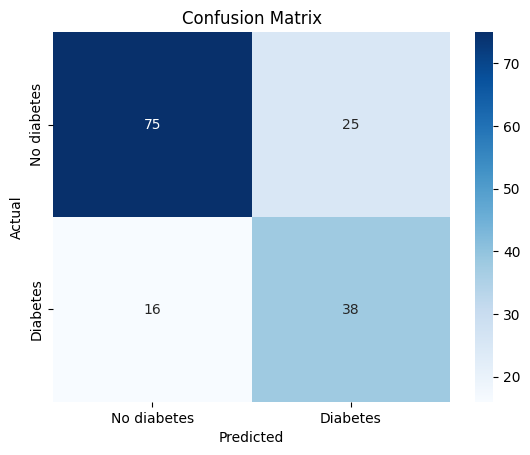

TN = 75  FP = 25
FN = 16  TP = 38


In [14]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No diabetes", "Diabetes"],
            yticklabels=["No diabetes", "Diabetes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print("TN =", cm[0, 0], " FP =", cm[0, 1])
print("FN =", cm[1, 0], " TP =", cm[1, 1])

## ROC curve

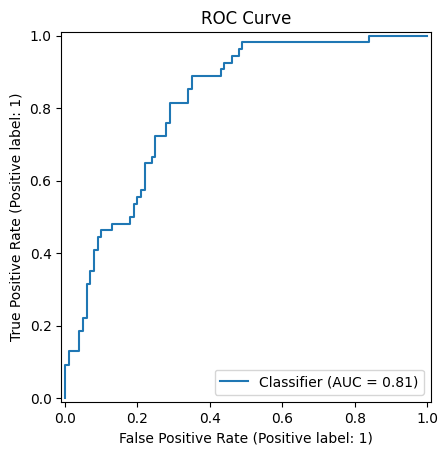

In [15]:
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve")
plt.show()

## 9. Important coefficients

Insulin                    -0.044609
BloodPressure              -0.014612
SkinThickness               0.013980
Age                         0.186434
DiabetesPedigreeFunction    0.287734
Pregnancies                 0.372902
BMI                         0.709592
Glucose                     1.183483
dtype: float64


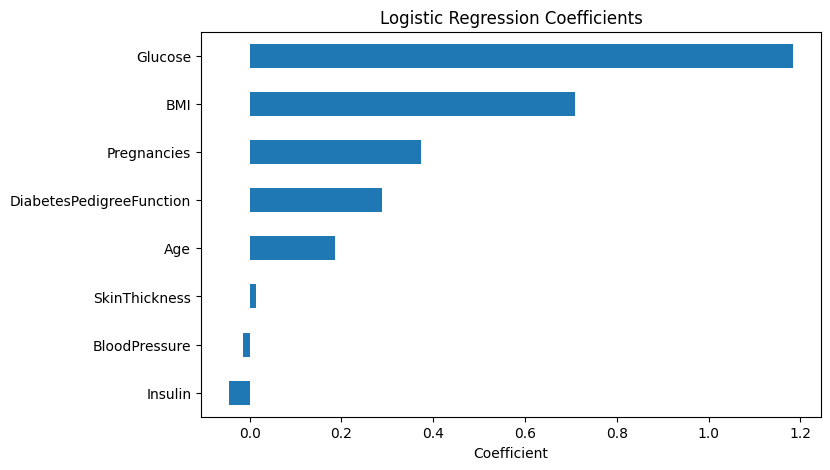

In [16]:
coefficients = pd.Series(
    model.named_steps["classifier"].coef_[0],
    index=X.columns
).sort_values()

print(coefficients)

coefficients.plot(kind="barh", figsize=(8, 5))
plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.show()